# EcoBuild: Testing the Model on Designs It Has Never Seen
**Notebook, update 3: Machine Learning / Production Lead**

**The question:** the prototype app reports very high accuracy (heating R² 0.998, cooling R² 0.981). Does that hold for a *new* building design?

**Why it might not:** the dataset has 768 rows, but they are really **192 designs, each simulated facing four directions**. A random 80/20 split can put one orientation of a design in training and another in testing, so the model has effectively already seen the test building.

**What this notebook does**
1. Shows the four-orientation structure in the data.
2. Re-tests the prototype's model two ways: random split vs. whole designs held out.
3. Re-tunes the model using validation that keeps each design's four orientations together.
4. Compares the settings, and the three model types, on designs that were held out from training and tuning.
5. Explains the predictions with SHAP, using the same method as the app.
6. Exports a model bundle in the same format as the app's `models/` folder, so it can be dropped in.

Everything uses the same data, features and model pipeline as the prototype. *Running time in Colab: about 5 to 10 minutes.*

## 1. Setup

In [1]:
import os, sys, json, shutil, platform, datetime, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

try:
    import shap
except ImportError:                      # Colab: install it the first time
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "-q"])
    import shap

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Chart style: validated categorical colors (blue, orange, aqua), quiet grid, text in neutral ink
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

def grouped_bars(ax, categories, series, colors, fmt="{:.2f}", ylabel=""):
    """Grouped bars with a thin surface-colored gap between bars and a value label on each bar."""
    n = len(series)
    width = 0.8 / n
    x = np.arange(len(categories))
    for i, ((name, vals), color) in enumerate(zip(series.items(), colors)):
        pos = x - 0.4 + width * (i + 0.5)
        bars = ax.bar(pos, vals, width=width, color=color, edgecolor=SURFACE, linewidth=2, label=name)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v),
                    ha="center", va="bottom", fontsize=9, color=INK_2)
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=n)

print("Setup complete. scikit-learn", __import__("sklearn").__version__, "| shap", shap.__version__)

Setup complete. scikit-learn 1.9.1 | shap 0.54.1


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the data
Same UCI Energy Efficiency file as before (`ENB2012_data.xlsx`). Columns are renamed to the same names the prototype uses.

*In Google Colab, run the cell and pick the file when prompted. Running locally, keep the file next to this notebook.*

In [2]:
FILE = "ENB2012_data.xlsx"
if not os.path.exists(FILE):
    from google.colab import files       # only works in Colab
    files.upload()

raw = pd.read_excel(FILE)
df = raw.rename(columns={
    "X1": "Relative_Compactness", "X2": "Surface_Area", "X3": "Wall_Area", "X4": "Roof_Area",
    "X5": "Overall_Height", "X6": "Orientation", "X7": "Glazing_Area",
    "X8": "Glazing_Area_Distribution", "Y1": "Heating_Load", "Y2": "Cooling_Load",
})

FEATURES = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height",
            "Orientation", "Glazing_Area", "Glazing_Area_Distribution"]
TARGETS = ["Heating_Load", "Cooling_Load"]
SHAPE_COLS = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height"]
DESIGN_COLS = [c for c in FEATURES if c != "Orientation"]     # everything that defines a design except direction

print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()))
df.head()

Shape: (768, 10) | missing values: 0


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 3. The data is 192 designs, each facing four directions
A "design" here means every input except orientation. Giving each design an ID shows how the rows are grouped.

In [3]:
df["design_id"] = df.groupby(DESIGN_COLS).ngroup()

per_design = df.groupby("design_id").size()
print(f"Rows: {len(df)}  |  distinct designs: {df.design_id.nunique()}  |  rows per design: {sorted(per_design.unique())}")

print("\nOne design, four orientations (orientation 2, 3, 4, 5 = North, East, South, West):")
display(df[df.design_id == df.design_id.iloc[0]][["Orientation", "Heating_Load", "Cooling_Load"]])

spread = df.groupby("design_id")[TARGETS].agg(lambda s: s.max() - s.min())
print("Average gap between a design's highest and lowest orientation:")
print(spread.mean().round(2).to_string())
print("\nFor comparison, loads range from", df.Heating_Load.min(), "to", df.Cooling_Load.max())

Rows: 768  |  distinct designs: 192  |  rows per design: [np.int64(4)]

One design, four orientations (orientation 2, 3, 4, 5 = North, East, South, West):


,Orientation,Heating_Load,Cooling_Load
0,2,15.55,21.33
1,3,15.55,21.33
2,4,15.55,21.33
3,5,15.55,21.33


Average gap between a design's highest and lowest orientation:
Heating_Load    0.70
Cooling_Load    2.34

For comparison, loads range from 6.01 to 48.03


**What this means:** the four orientations of a design have very similar loads (often identical when there are no windows). If a random split puts three of them in training and one in testing, the model gets tested on something it has nearly seen. To measure how well the model handles a *new* design, all four orientations have to stay together on one side of the split.

## 4. Rebuild the prototype's model
This is the same feature engineering and model pipeline as the app (`ecobuild_core.py`), and the same tuned settings from the app's `metadata.json`.

In [4]:
NUM = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height",
       "Glazing_Area", "Wall_to_Roof_Ratio", "Envelope_per_Height", "Glazing_x_Height", "Is_Two_Story"]
CAT = ["Orientation", "Glazing_Area_Distribution"]

def engineer_features(data):
    out = data.copy()
    out["Wall_to_Roof_Ratio"] = out["Wall_Area"] / out["Roof_Area"]
    out["Envelope_per_Height"] = out["Surface_Area"] / out["Overall_Height"]
    out["Glazing_x_Height"] = out["Glazing_Area"] * out["Overall_Height"]
    out["Is_Two_Story"] = (out["Overall_Height"] >= 7.0).astype(int)
    out["Orientation"] = out["Orientation"].astype(int).astype(str)
    out["Glazing_Area_Distribution"] = out["Glazing_Area_Distribution"].astype(int).astype(str)
    return out

def model_input(raw_rows):
    return engineer_features(raw_rows[FEATURES])[NUM + CAT]

def make_pipeline(model):
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), NUM),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
    ])
    return Pipeline([("prep", prep), ("model", model)])

def gb(params=None):
    return GradientBoostingRegressor(random_state=RANDOM_STATE, **(params or {}))

def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

# The prototype's tuned settings (from its metadata.json)
PROTOTYPE_PARAMS = {
    "Heating_Load": dict(learning_rate=0.05, max_depth=5, n_estimators=600, subsample=1.0),
    "Cooling_Load": dict(learning_rate=0.05, max_depth=5, n_estimators=600, subsample=0.8),
}
X_all = model_input(df)
print("Model input columns:", list(X_all.columns))

Model input columns: ['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Glazing_Area', 'Wall_to_Roof_Ratio', 'Envelope_per_Height', 'Glazing_x_Height', 'Is_Two_Story', 'Orientation', 'Glazing_Area_Distribution']


## 5. Stress test: same model, two ways of testing
The prototype's tuned model, tested with 5-fold cross-validation two ways on all 768 rows:
- **Random split:** rows are shuffled, so a design's orientations can land on both sides.
- **Whole designs held out:** all four orientations of a design stay together. Designs are assigned to folds at random, because a fixed assignment can group similar designs together and make one number look better or worse than it should.

,Target,Test,MAE,RMSE,R2
0,Heating Load,Random split,0.232,0.360,0.999
1,Heating Load,Whole designs held out,0.431,0.780,0.993
2,Cooling Load,Random split,0.523,0.877,0.991
3,Cooling Load,Whole designs held out,0.658,0.949,0.990


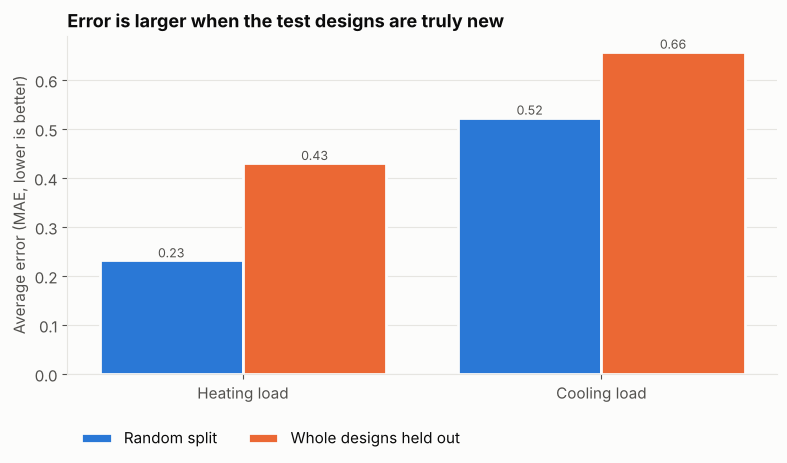

In [5]:
rows = []
for t in TARGETS:
    for label, splitter, groups in [
        ("Random split", KFold(5, shuffle=True, random_state=RANDOM_STATE), None),
        ("Whole designs held out", GroupKFold(5, shuffle=True, random_state=RANDOM_STATE), df["design_id"]),
    ]:
        fold_scores = []
        for tr, te in splitter.split(X_all, df[t], groups):
            pipe = make_pipeline(gb(PROTOTYPE_PARAMS[t])).fit(X_all.iloc[tr], df[t].iloc[tr])
            fold_scores.append(scores(df[t].iloc[te], pipe.predict(X_all.iloc[te])))
        avg = pd.DataFrame(fold_scores).mean()
        rows.append({"Target": t.replace("_", " "), "Test": label, "MAE": avg.MAE, "RMSE": avg.RMSE, "R2": avg.R2})
stress = pd.DataFrame(rows)
display(stress.round(3))

fig, ax = plt.subplots(figsize=(8, 4.8))
cats = ["Heating load", "Cooling load"]
series = {lab: stress[stress.Test == lab].MAE.values for lab in ["Random split", "Whole designs held out"]}
grouped_bars(ax, cats, series, [BLUE, ORANGE], ylabel="Average error (MAE, lower is better)")
ax.set_title("Error is larger when the test designs are truly new")
plt.tight_layout(); plt.show()

## 6. A fair split: hold out whole designs
Keep 20% of the *designs* (all four orientations each) out of everything: training and tuning. This is the test set used for all results from here on.

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, groups=df["design_id"]))
train, test = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()

assert set(train.design_id).isdisjoint(set(test.design_id)), "a design appears on both sides!"
print(f"Training: {train.design_id.nunique()} designs ({len(train)} rows)")
print(f"Testing:  {test.design_id.nunique()} designs ({len(test)} rows), none seen during training or tuning")

X_train, X_test = model_input(train), model_input(test)

Training: 153 designs (612 rows)
Testing:  39 designs (156 rows), none seen during training or tuning


## 7. Re-tune with grouped cross-validation
The search tries 40 random combinations of settings for each target. Each one is scored with 5-fold cross-validation **on the training designs only**, with each design's orientations kept together, so the settings are chosen by how well they handle unseen designs. The held-out test designs are not touched.

*This is the slowest cell: a few minutes.*

In [7]:
param_dist = {
    "model__n_estimators": [200, 300, 400, 600],
    "model__learning_rate": [0.02, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__subsample": [0.6, 0.8, 1.0],
    "model__min_samples_leaf": [1, 3, 5, 10],
}

NEW_PARAMS, search_tables = {}, {}
for t in TARGETS:
    search = RandomizedSearchCV(
        make_pipeline(gb()), param_dist, n_iter=40, cv=GroupKFold(n_splits=5),
        scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1, refit=False,
    )
    search.fit(X_train, train[t], groups=train["design_id"])
    res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").reset_index(drop=True)
    res["CV MAE"] = -res["mean_test_score"]
    for k in param_dist:
        res[k.replace("model__", "")] = res["params"].apply(lambda p, k=k: p[k])
    search_tables[t] = res
    NEW_PARAMS[t] = {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v)
                     for k, v in res.loc[0, "params"].items()}
    print(f"\n{t}: best settings {NEW_PARAMS[t]}  (cross-validated MAE {res.loc[0, 'CV MAE']:.3f})")
    display(res[["CV MAE"] + [k.replace("model__", "") for k in param_dist]].head(5).round(3))


Heating_Load: best settings {'subsample': 0.8, 'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 3, 'learning_rate': 0.03}  (cross-validated MAE 0.397)


,CV MAE,n_estimators,learning_rate,max_depth,subsample,min_samples_leaf
0,0.397,300,0.03,3,0.8,5
1,0.401,600,0.03,3,0.8,10
2,0.406,300,0.10,2,0.8,3
3,0.419,200,0.10,2,0.6,1
4,0.430,200,0.05,4,1.0,5



Cooling_Load: best settings {'subsample': 1.0, 'n_estimators': 400, 'min_samples_leaf': 10, 'max_depth': 5, 'learning_rate': 0.1}  (cross-validated MAE 0.874)


,CV MAE,n_estimators,learning_rate,max_depth,subsample,min_samples_leaf
0,0.874,400,0.10,5,1.0,10
1,0.885,200,0.10,6,0.8,10
2,0.887,400,0.10,6,0.8,10
3,0.895,600,0.02,5,0.6,3
4,0.909,600,0.03,6,0.6,10


## 8. Do the re-tuned settings help on the held-out designs?
Three sets of settings, each trained on the training designs and tested once on the held-out designs:
- **Default:** scikit-learn's out-of-the-box settings
- **Prototype's tuned settings:** what the app uses now
- **Re-tuned:** chosen by grouped cross-validation in section 7

With only about 38 test designs, small differences can be noise, so the bootstrap below measures how large that noise is.

,Target,Settings,MAE,RMSE,R2
0,Heating Load,Default settings,0.486,0.690,0.995
1,Heating Load,Prototype's tuned settings,0.541,1.101,0.987
2,Heating Load,Re-tuned (grouped CV),0.424,0.614,0.996
3,Cooling Load,Default settings,1.240,1.741,0.965
4,Cooling Load,Prototype's tuned settings,0.815,1.220,0.983
5,Cooling Load,Re-tuned (grouped CV),0.849,1.197,0.983


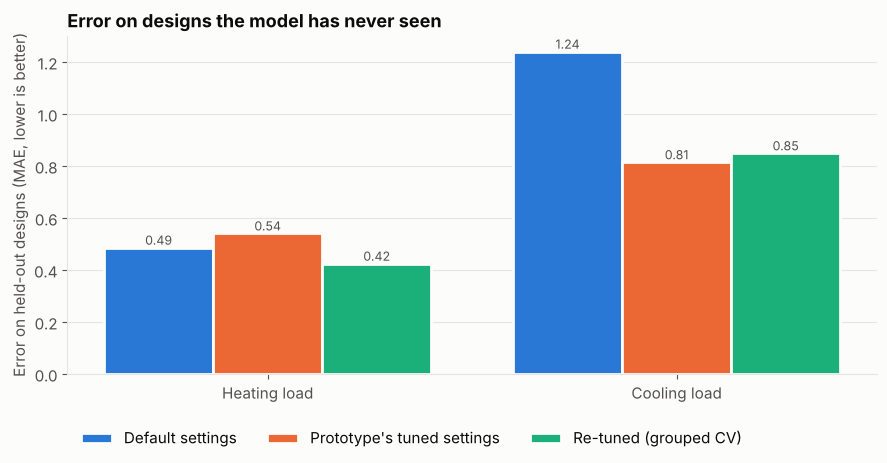

In [8]:
candidates = {
    "Default settings": lambda t: {},
    "Prototype's tuned settings": lambda t: PROTOTYPE_PARAMS[t],
    "Re-tuned (grouped CV)": lambda t: NEW_PARAMS[t],
}
cmp_rows, abs_err = [], {}
for t in TARGETS:
    for name, get_params in candidates.items():
        pipe = make_pipeline(gb(get_params(t))).fit(X_train, train[t])
        pred = pipe.predict(X_test)
        abs_err[(t, name)] = np.abs(test[t].values - pred)
        cmp_rows.append({"Target": t.replace("_", " "), "Settings": name, **scores(test[t], pred)})
cmp = pd.DataFrame(cmp_rows)
display(cmp.round(3))

fig, ax = plt.subplots(figsize=(9, 4.8))
series = {n: cmp[cmp.Settings == n].MAE.values for n in candidates}
grouped_bars(ax, ["Heating load", "Cooling load"], series, [BLUE, ORANGE, AQUA],
             ylabel="Error on held-out designs (MAE, lower is better)")
ax.set_title("Error on designs the model has never seen")
plt.tight_layout(); plt.show()

In [9]:
# How much of the gap between the prototype's settings and the re-tuned settings could be noise?
# Paired bootstrap over designs: resample the 38 or so test designs many times.
rng = np.random.default_rng(RANDOM_STATE)
ids = test["design_id"].values
boot_rows = []
for t in TARGETS:
    per_design = lambda name: pd.Series(abs_err[(t, name)]).groupby(ids).mean().values
    diff = per_design("Re-tuned (grouped CV)") - per_design("Prototype's tuned settings")
    means = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(5000)]
    lo, hi = np.percentile(means, [2.5, 97.5])
    boot_rows.append({"Target": t.replace("_", " "), "MAE change (re-tuned minus prototype)": diff.mean(),
                      "95% range low": lo, "95% range high": hi,
                      "Clearly different?": "yes" if (lo > 0 or hi < 0) else "not clearly"})
display(pd.DataFrame(boot_rows).round(3))

,Target,MAE change (re-tuned minus prototype),95% range low,95% range high,Clearly different?
0,Heating Load,-0.116,-0.432,0.115,not clearly
1,Cooling Load,0.034,-0.074,0.140,not clearly


*How to read this:* a negative change means the re-tuned settings have lower error. If the 95% range includes zero, the difference could be noise from having only a few dozen test designs, and the honest conclusion is that the two settings perform about the same.

## 9. Compare the three model types on held-out designs
Same comparison the app's Performance tab shows (Linear Regression, Random Forest, Gradient Boosting), now on designs held out from training. Gradient Boosting uses the re-tuned settings.

,Target,Model,MAE,RMSE,R2
0,Heating Load,Linear Regression,2.070,2.537,0.930
1,Heating Load,Random Forest,0.581,0.956,0.990
2,Heating Load,Gradient Boosting,0.424,0.614,0.996
3,Cooling Load,Linear Regression,2.556,3.317,0.872
4,Cooling Load,Random Forest,1.549,2.269,0.940
5,Cooling Load,Gradient Boosting,0.849,1.197,0.983


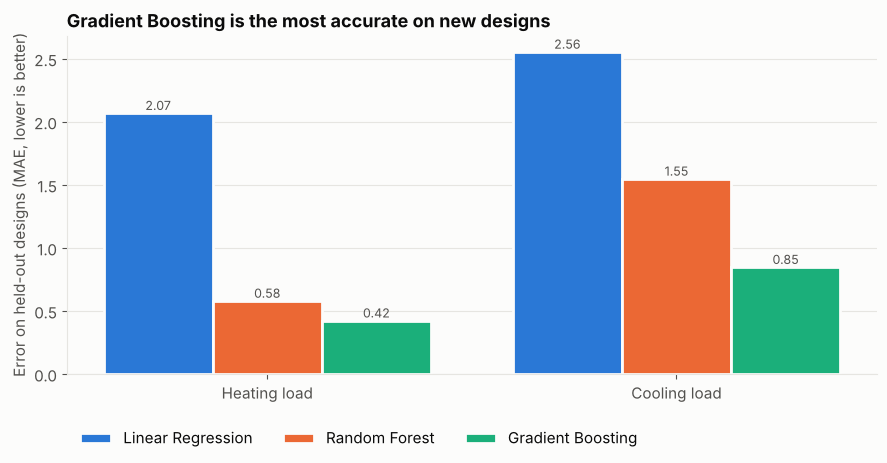

In [10]:
final_makers = {
    "Linear Regression": lambda t: LinearRegression(),
    "Random Forest": lambda t: RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": lambda t: gb(NEW_PARAMS[t]),
}
final_models = {}                 # only the Gradient Boosting pipelines are exported
metric_rows, test_preds = [], {}
for t in TARGETS:
    for name, maker in final_makers.items():
        pipe = make_pipeline(maker(t)).fit(X_train, train[t])
        pred = pipe.predict(X_test)
        test_preds[(t, name)] = pred
        metric_rows.append({"Target": t.replace("_", " "), "Model": name, **scores(test[t], pred)})
        if name == "Gradient Boosting":
            final_models[t] = pipe
model_table = pd.DataFrame(metric_rows)
display(model_table.round(3))

fig, ax = plt.subplots(figsize=(9, 4.8))
names = list(final_makers)
series = {n: model_table[model_table.Model == n].MAE.values for n in names}
grouped_bars(ax, ["Heating load", "Cooling load"], series, [BLUE, ORANGE, AQUA],
             ylabel="Error on held-out designs (MAE, lower is better)")
ax.set_title("Gradient Boosting is the most accurate on new designs")
plt.tight_layout(); plt.show()

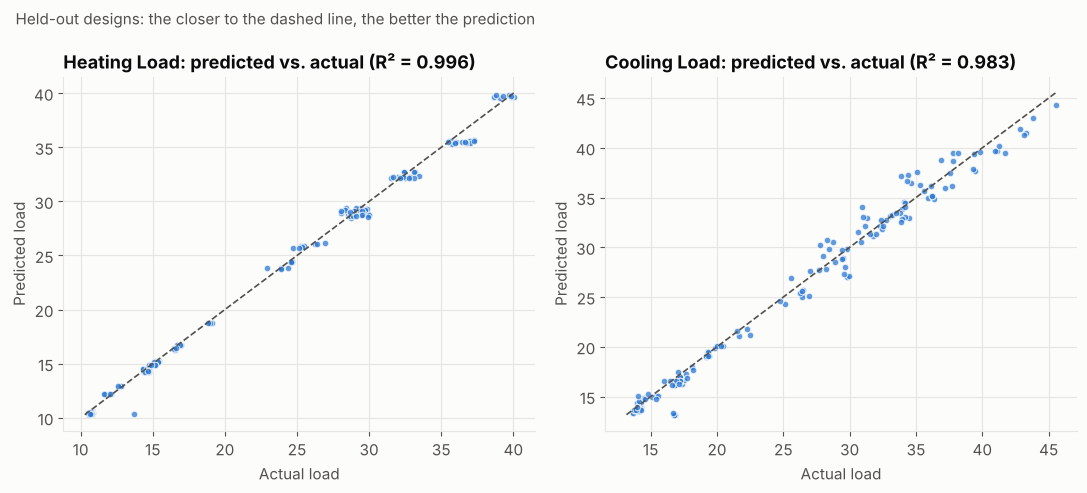

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, t in zip(axes, TARGETS):
    pred = test_preds[(t, "Gradient Boosting")]
    ax.scatter(test[t], pred, s=22, color=BLUE, alpha=0.75, edgecolor=SURFACE, linewidth=0.8)
    lims = [min(test[t].min(), pred.min()), max(test[t].max(), pred.max())]
    ax.plot(lims, lims, color=INK_2, linestyle="--", linewidth=1.2)
    r2 = r2_score(test[t], pred)
    ax.set_title(f"{t.replace('_', ' ')}: predicted vs. actual (R² = {r2:.3f})")
    ax.set_xlabel("Actual load")
    ax.set_ylabel("Predicted load")
plt.suptitle("Held-out designs: the closer to the dashed line, the better the prediction", x=0.02, ha="left", fontsize=11, color=INK_2)
plt.tight_layout(); plt.show()

## 10. What drives the predictions? (SHAP, same method as the app)
SHAP splits each prediction into the contribution of each design feature. The app uses the same exact-SHAP method on the 8 original design features. Here it is computed on the held-out designs. *A minute or two.*

ExactExplainer explainer:  68%|██████▊   | 106/156 [00:00<?, ?it/s]

ExactExplainer explainer:  70%|██████▉   | 109/156 [00:10<00:02, 16.62it/s]

ExactExplainer explainer:  71%|███████   | 111/156 [00:10<00:03, 13.49it/s]

ExactExplainer explainer:  72%|███████▏  | 113/156 [00:10<00:03, 12.22it/s]

ExactExplainer explainer:  74%|███████▎  | 115/156 [00:10<00:03, 12.25it/s]

ExactExplainer explainer:  75%|███████▌  | 117/156 [00:10<00:03, 12.37it/s]

... (17 outputs left out)

ExactExplainer explainer:  98%|█████████▊| 153/156 [00:14<00:00, 10.57it/s]

ExactExplainer explainer:  99%|█████████▉| 155/156 [00:14<00:00, 10.98it/s]

ExactExplainer explainer: 157it [00:14, 11.29it/s]                         

ExactExplainer explainer: 157it [00:14,  3.51it/s]

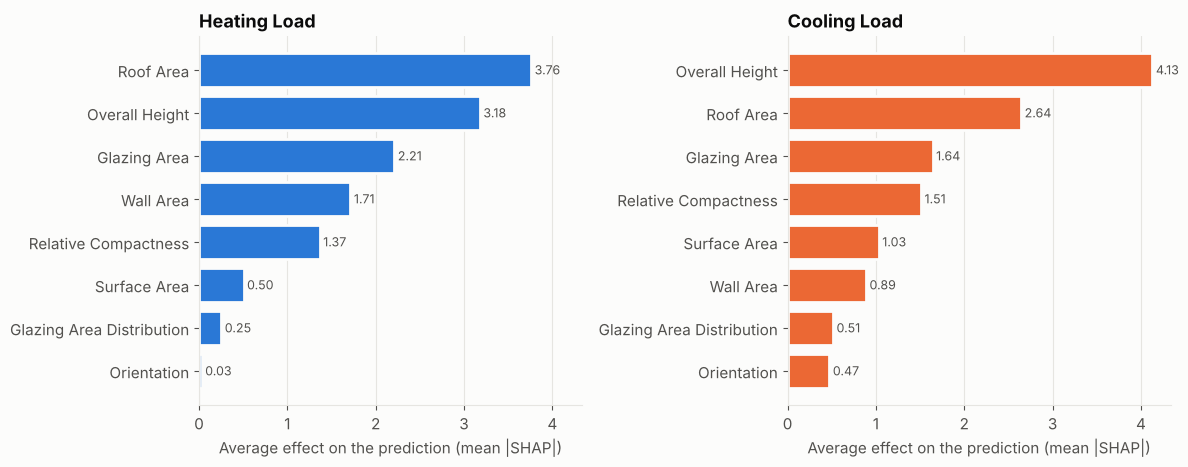

Target,Cooling_Load,Heating_Load
Feature,,
Roof_Area,2.64,3.76
Overall_Height,4.13,3.18
Glazing_Area,1.64,2.21
Wall_Area,0.89,1.71
Relative_Compactness,1.51,1.37
Surface_Area,1.03,0.50
Glazing_Area_Distribution,0.51,0.25
Orientation,0.47,0.03


In [12]:
background = train[FEATURES].sample(100, random_state=RANDOM_STATE)       # saved with the bundle

def explain(model, rows):
    f = lambda arr: model.predict(model_input(pd.DataFrame(arr, columns=FEATURES)))
    bg = background.sample(min(50, len(background)), random_state=0)
    explainer = shap.explainers.Exact(f, shap.maskers.Independent(bg, max_samples=50))
    return explainer(rows[FEATURES])

shap_importance, shap_base = [], {}
for t in TARGETS:
    sv = explain(final_models[t], test)
    shap_base[t] = float(sv.base_values[0])
    for feat, val in zip(FEATURES, np.abs(sv.values).mean(axis=0)):
        shap_importance.append({"Target": t, "Feature": feat, "Mean_abs_SHAP": float(val)})
imp = pd.DataFrame(shap_importance)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, t, color in zip(axes, TARGETS, [BLUE, ORANGE]):
    sub = imp[imp.Target == t].sort_values("Mean_abs_SHAP")
    ax.barh(sub.Feature.str.replace("_", " "), sub.Mean_abs_SHAP, color=color, edgecolor=SURFACE, linewidth=2)
    for y, v in enumerate(sub.Mean_abs_SHAP):
        ax.text(v, y, f" {v:.2f}", va="center", fontsize=9, color=INK_2)
    ax.set_title(f"{t.replace('_', ' ')}")
    ax.set_xlabel("Average effect on the prediction (mean |SHAP|)")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

display(imp.pivot(index="Feature", columns="Target", values="Mean_abs_SHAP")
        .sort_values("Heating_Load", ascending=False).round(2))

*Note:* Surface area, roof area and compactness are strongly related to one another, so SHAP shares credit among them. Read them as a group describing the building's form, not as separate levers.

## 11. Export a drop-in bundle for the app
This writes the same files as the app's `models/` folder, using the same names and the same `metadata.json` fields the app reads. Unzip `ecobuild_models_v2.zip` into the app's `models/` folder, replacing the existing files.

The app's retrain fallback and Performance tab text also need a small update to describe the grouped split (see the instructions that came with this notebook).

In [13]:
BUNDLE = "ecobuild_models_v2"
shutil.rmtree(BUNDLE, ignore_errors=True)
os.makedirs(BUNDLE)

for t in TARGETS:
    joblib.dump(final_models[t], f"{BUNDLE}/{t.lower()}_model.joblib")
df[FEATURES + TARGETS].to_csv(f"{BUNDLE}/ENB2012_data.csv", index=False)
background.to_csv(f"{BUNDLE}/shap_background.csv", index=False)

valid_shapes = df[SHAPE_COLS].drop_duplicates().sort_values("Relative_Compactness").reset_index(drop=True)

meta = {
    "created": datetime.date.today().isoformat(),
    "random_state": RANDOM_STATE,
    "split": {
        "method": "GroupShuffleSplit by design (all four orientations together)",
        "test_size": 0.2,
        "n_train_designs": int(train.design_id.nunique()), "n_test_designs": int(test.design_id.nunique()),
        "n_train_rows": int(len(train)), "n_test_rows": int(len(test)),
    },
    "tuning": "RandomizedSearchCV, 40 candidates, 5-fold GroupKFold on training designs, scored by MAE",
    "features": FEATURES, "num_features": NUM, "cat_features": CAT, "targets": TARGETS,
    "best_model": {t: "Gradient Boosting" for t in TARGETS},
    "best_params": NEW_PARAMS,
    "test_metrics": [{"Target": r["Target"], "Model": r["Model"], "MAE": float(r["MAE"]),
                      "RMSE": float(r["RMSE"]), "R2": float(r["R2"])} for r in metric_rows],
    "shap_importance": shap_importance,
    "shap_base_value": shap_base,
    "valid_shapes": json.loads(valid_shapes.to_json(orient="records")),
    "versions": {"python": platform.python_version(), "scikit-learn": __import__("sklearn").__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "shap": shap.__version__},
}
with open(f"{BUNDLE}/metadata.json", "w") as fh:
    json.dump(meta, fh, indent=2)

shutil.make_archive("ecobuild_models_v2", "zip", BUNDLE)
print("Bundle files:", sorted(os.listdir(BUNDLE)))

# Reload the saved models and confirm they reproduce the reported results
for t in TARGETS:
    reloaded = joblib.load(f"{BUNDLE}/{t.lower()}_model.joblib")
    assert np.allclose(reloaded.predict(X_test), test_preds[(t, "Gradient Boosting")]), "reload mismatch"
print("Reload check passed: saved models reproduce the reported predictions exactly.")

try:
    from google.colab import files
    files.download("ecobuild_models_v2.zip")
except ImportError:
    print("Not in Colab: ecobuild_models_v2.zip is saved next to this notebook.")

Bundle files: ['ENB2012_data.csv', 'cooling_load_model.joblib', 'heating_load_model.joblib', 'metadata.json', 'shap_background.csv']


Reload check passed: saved models reproduce the reported predictions exactly.
Not in Colab: ecobuild_models_v2.zip is saved next to this notebook.


## 12. Findings
*(Fill these in after running the notebook with your own numbers.)*
- Accuracy when the test designs are truly new (Gradient Boosting): heating R² ___, MAE ___; cooling R² ___, MAE ___
- Compared with the random-split numbers the prototype shows: ___
- Re-tuned vs. the prototype's settings: ___ (use the bootstrap table: is the difference clear, or within noise?)
- Features that drive the predictions: ___

## 13. Next steps
- [ ] Share `ecobuild_models_v2.zip` and the app patch with the teammate who maintains the prototype
- [ ] Update the Performance tab so it states that results are on held-out designs
- [ ] Optional: refit the final model on all 192 designs before a public launch (the numbers above are the estimate of how it will do on new designs)
- [ ] Optional: test on real buildings, since this dataset is simulated for one climate